# Improving the end-to-end IMDB classifier

Activity from *Tokenizers, Classification, and Visualization*
([course page](https://tiagoft.github.io/nlp_course/language_models/03-end_to_end_neural_networks/)).

Pipeline: **SentencePiece → `nn.Embedding` → mean over time → `nn.Linear`**, trained with
binary cross-entropy and Adam. Each experiment changes **one** parameter and holds the rest at the baseline:

| Parameter | Baseline | Values tested |
|---|---|---|
| Vocabulary size | 4000 | 100, 500, 1000, 4000, 16000 |
| Train set size | 5000 | 100, 500, 2000, 5000, 25000 |
| Embedding dimension | 32 | 2, 8, 32, 128, 512 |

Fixed for every run: max length 256 tokens, batch size 64, Adam (lr 1e-2), 20 epochs, and a fixed
evaluation set of 5000 reviews from the IMDB **test** split. Each configuration runs with 3 seeds.
The tokenizer is always trained on that run's training texts, never on test data.

Differences from the class notebook:
- mini-batches instead of one full-batch step per epoch
- a **masked** mean, so `<PAD>` tokens don't dilute short reviews
- a tokenizer trained on IMDB instead of a Shakespeare excerpt

In [1]:
import io, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import sentencepiece as spm
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score

torch.set_num_threads(8)
DEVICE = 'cpu'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
RES = Path('results'); RES.mkdir(exist_ok=True)
TOK = Path('tokenizers'); TOK.mkdir(exist_ok=True)

BASE = dict(vocab_size=4000, n_train=5000, embedding_dim=32, model='mean')
MAX_LEN, BATCH, LR, EPOCHS, N_EVAL = 256, 64, 1e-2, 20, 5000
SEEDS = [0, 1, 2]

## Data
IMDB parquet files from `stanfordnlp/imdb` on Hugging Face, cached in `data/`.

In [2]:
def load_split(split):
    p = Path(f'data/imdb_{split}.parquet')
    if not p.exists():
        p.parent.mkdir(exist_ok=True)
        url = f'https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/{split}-00000-of-00001.parquet'
        pd.read_parquet(url).to_parquet(p)
    return pd.read_parquet(p)

train_full = load_split('train').sample(frac=1, random_state=42).reset_index(drop=True)
test_df = load_split('test').sample(N_EVAL, random_state=42).reset_index(drop=True)
print(train_full.shape, test_df.shape, test_df.label.mean())

(25000, 2) (5000, 2) 0.497


## Tokenizer, padding, model

In [3]:
_tok_cache = {}
def get_tokenizer(texts, vocab_size, tag):
    key = (vocab_size, tag)
    if key not in _tok_cache:
        prefix = str(TOK / f'spm_v{vocab_size}_{tag}')
        spm.SentencePieceTrainer.train(
            sentence_iterator=iter(texts), model_prefix=prefix, vocab_size=vocab_size,
            user_defined_symbols=['<PAD>'], hard_vocab_limit=False,
            input_sentence_size=2_000_000, shuffle_input_sentence=True, minloglevel=2)
        _tok_cache[key] = spm.SentencePieceProcessor(model_file=prefix + '.model')
    return _tok_cache[key]

def pad_to_len(seqs, pad_idx, max_len):
    out = torch.full((len(seqs), max_len), pad_idx, dtype=torch.long)
    for i, s in enumerate(seqs):
        s = s[:max_len]
        out[i, :len(s)] = torch.tensor(s, dtype=torch.long)
    return out

def encode(sp, texts):
    pad = sp.piece_to_id('<PAD>')
    return pad_to_len(sp.encode(list(texts)), pad, MAX_LEN), pad


class MeanClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, pad_idx):
        super().__init__()
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.clf = nn.Linear(embedding_dim, 1)

    def forward(self, x, return_embeddings=False):
        mask = (x != self.pad_idx).unsqueeze(-1).float()
        e = (self.embedding(x) * mask).sum(1) / mask.sum(1).clamp(min=1)
        logits = self.clf(e).squeeze(-1)
        return (logits, e) if return_embeddings else logits


class RNNClassifier(nn.Module):
    """Extension: replace the mean with a (bi)GRU/LSTM; document vector = masked mean of hidden states."""
    def __init__(self, vocab_size, embedding_dim, pad_idx, cell='gru', hidden=64):
        super().__init__()
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        rnn = {'gru': nn.GRU, 'lstm': nn.LSTM, 'rnn': nn.RNN}[cell]
        self.rnn = rnn(embedding_dim, hidden, batch_first=True, bidirectional=True)
        self.clf = nn.Linear(2 * hidden, 1)

    def forward(self, x, return_embeddings=False):
        mask = (x != self.pad_idx).unsqueeze(-1).float()
        h, _ = self.rnn(self.embedding(x))
        e = (h * mask).sum(1) / mask.sum(1).clamp(min=1)
        logits = self.clf(e).squeeze(-1)
        return (logits, e) if return_embeddings else logits

## Training loop
Records train/eval loss and eval accuracy every epoch, plus eval document embeddings at the end.

In [4]:
def run(vocab_size, n_train, embedding_dim, model='mean', seed=0, epochs=EPOCHS, lr=LR):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    tr = train_full.sample(n_train, random_state=seed)
    sp = get_tokenizer(tr.text.tolist(), vocab_size, f'n{n_train}_s{seed}')
    Xtr, pad = encode(sp, tr.text); ytr = torch.tensor(tr.label.values, dtype=torch.float)
    Xte, _ = encode(sp, test_df.text); yte = torch.tensor(test_df.label.values, dtype=torch.float)
    V = sp.get_piece_size()
    net = MeanClassifier(V, embedding_dim, pad) if model == 'mean' else RNNClassifier(V, embedding_dim, pad, cell=model)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xtr)); tot = 0.0
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.binary_cross_entropy_with_logits(net(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        net.eval()
        with torch.no_grad():
            logits, emb = [], []
            for i in range(0, len(Xte), 512):
                l, e = net(Xte[i:i + 512], return_embeddings=True); logits.append(l); emb.append(e)
            logits = torch.cat(logits)
            ev = F.binary_cross_entropy_with_logits(logits, yte).item()
            pred = (logits > 0).long().numpy()
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(Xtr), eval_loss=ev,
                         eval_acc=accuracy_score(yte, pred), eval_f1=f1_score(yte, pred)))
    with torch.no_grad():
        _, tr_emb = net(Xtr[:2000], return_embeddings=True)
    h = pd.DataFrame(hist)
    return dict(hist=h, final_acc=h.eval_acc.iloc[-1], best_acc=h.eval_acc.max(),
                final_f1=h.eval_f1.iloc[-1], best_epoch=int(h.eval_acc.idxmax()) + 1,
                n_params=sum(p.numel() for p in net.parameters()), secs=time.time() - t0,
                ev_emb=torch.cat(emb).numpy(), ev_y=yte.numpy(),
                tr_emb=tr_emb.numpy(), tr_y=ytr[:2000].numpy(), actual_vocab=V)

## Experiment helpers

In [5]:
def sweep(param, values, seeds=SEEDS, **overrides):
    rows, keep = [], {}
    for v in values:
        for s in seeds:
            cfg = {**BASE, **overrides, param: v}
            r = run(seed=s, **cfg)
            rows.append(dict(param=param, value=v, seed=s, final_acc=r['final_acc'], best_acc=r['best_acc'],
                             final_f1=r['final_f1'], best_epoch=r['best_epoch'], n_params=r['n_params'],
                             secs=r['secs'], actual_vocab=r['actual_vocab']))
            if s == seeds[0]:
                keep[v] = r
            print(f'{param}={v} seed={s}: final acc={r["final_acc"]:.3f} best={r["best_acc"]:.3f} '
                  f'(ep {r["best_epoch"]}) {r["secs"]:.0f}s')
    df = pd.DataFrame(rows)
    df.to_csv(RES / f'{param}.csv', index=False)
    return df, keep

def summarize(df):
    return (df.groupby('value')
              .agg(final_acc=('final_acc', 'mean'), final_std=('final_acc', 'std'),
                   best_acc=('best_acc', 'mean'), best_epoch=('best_epoch', 'mean'),
                   n_params=('n_params', 'first'), secs=('secs', 'mean'))
              .round(4))

def plot_sweep(param, df, keep, label):
    s = df.groupby('value')
    vals = list(keep)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
    x = np.arange(len(vals))
    ax[0].errorbar(x, s.final_acc.mean(), yerr=s.final_acc.std(), marker='o', capsize=4, label='final epoch')
    ax[0].plot(x, s.best_acc.mean(), marker='s', ls='--', label='best epoch')
    ax[0].set_xticks(x, vals); ax[0].set_xlabel(label); ax[0].set_ylabel('eval accuracy')
    ax[0].set_title('Eval accuracy (mean ± std, 3 seeds)'); ax[0].legend(); ax[0].grid(alpha=.3)
    cmap = plt.cm.viridis(np.linspace(0, .9, len(vals)))
    for c, v in zip(cmap, vals):
        h = keep[v]['hist']
        ax[1].plot(h.epoch, h.train_loss, color=c, ls='--')
        ax[1].plot(h.epoch, h.eval_loss, color=c, label=f'{v}')
        ax[2].plot(h.epoch, h.eval_acc, color=c, label=f'{v}')
    ax[1].set_title('Learning curves (solid = eval, dashed = train)'); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('BCE loss')
    ax[1].set_ylim(0, 1.2); ax[1].legend(title=label, fontsize=8); ax[1].grid(alpha=.3)
    ax[2].set_title('Eval accuracy per epoch'); ax[2].set_xlabel('epoch'); ax[2].legend(title=label, fontsize=8); ax[2].grid(alpha=.3)
    fig.tight_layout(); fig.savefig(FIG / f'{param}_curves.png', dpi=130); plt.show()

    fig, ax = plt.subplots(2, len(vals), figsize=(3.4 * len(vals), 6.4))
    for j, v in enumerate(vals):
        r = keep[v]
        for i, (E, y, name) in enumerate([(r['tr_emb'], r['tr_y'], 'train'), (r['ev_emb'], r['ev_y'], 'eval')]):
            P = E if E.shape[1] == 2 else PCA(2, random_state=0).fit(r['tr_emb']).transform(E)
            a = ax[i, j]
            for cls, col in [(0, 'tab:red'), (1, 'tab:blue')]:
                a.scatter(*P[y == cls][:1500].T, s=3, alpha=.4, c=col, label=f'class {cls}')
            a.set_title(f'{label}={v} ({name})', fontsize=9); a.set_xticks([]); a.set_yticks([])
    ax[0, 0].legend(markerscale=4, fontsize=8)
    fig.suptitle('Document embeddings, last epoch (PCA to 2D, fitted on train, when dim > 2)')
    fig.tight_layout(); fig.savefig(FIG / f'{param}_embeddings.png', dpi=110); plt.show()

## Experiment 1: vocabulary size

vocab_size=100 seed=0: final acc=0.620 best=0.622 (ep 8) 4s


vocab_size=100 seed=1: final acc=0.611 best=0.615 (ep 6) 4s


vocab_size=100 seed=2: final acc=0.609 best=0.617 (ep 17) 4s


vocab_size=500 seed=0: final acc=0.730 best=0.737 (ep 7) 4s


vocab_size=500 seed=1: final acc=0.728 best=0.731 (ep 5) 4s


...

vocab_size=4000 seed=2: final acc=0.791 best=0.815 (ep 5) 5s


vocab_size=16000 seed=0: final acc=0.811 best=0.823 (ep 4) 6s


vocab_size=16000 seed=1: final acc=0.811 best=0.828 (ep 4) 7s


vocab_size=16000 seed=2: final acc=0.814 best=0.824 (ep 5) 2s


,final_acc,final_std,best_acc,best_epoch,n_params,secs
value,,,,,,
100,0.6129,0.0059,0.6179,10.3333,3233,3.5833
500,0.7303,0.0024,0.7342,9.3333,16033,3.6148
1000,0.7629,0.0036,0.7724,5.3333,32033,3.6510
4000,0.7873,0.0044,0.8137,4.3333,128033,4.8328
16000,0.8122,0.0019,0.8251,4.3333,512033,4.8885


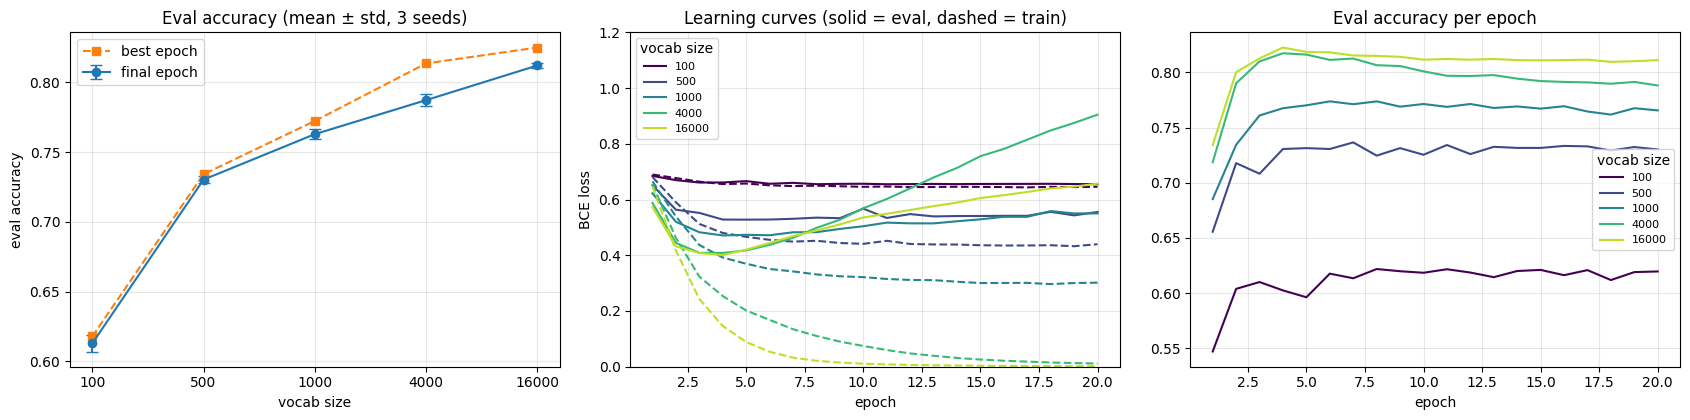

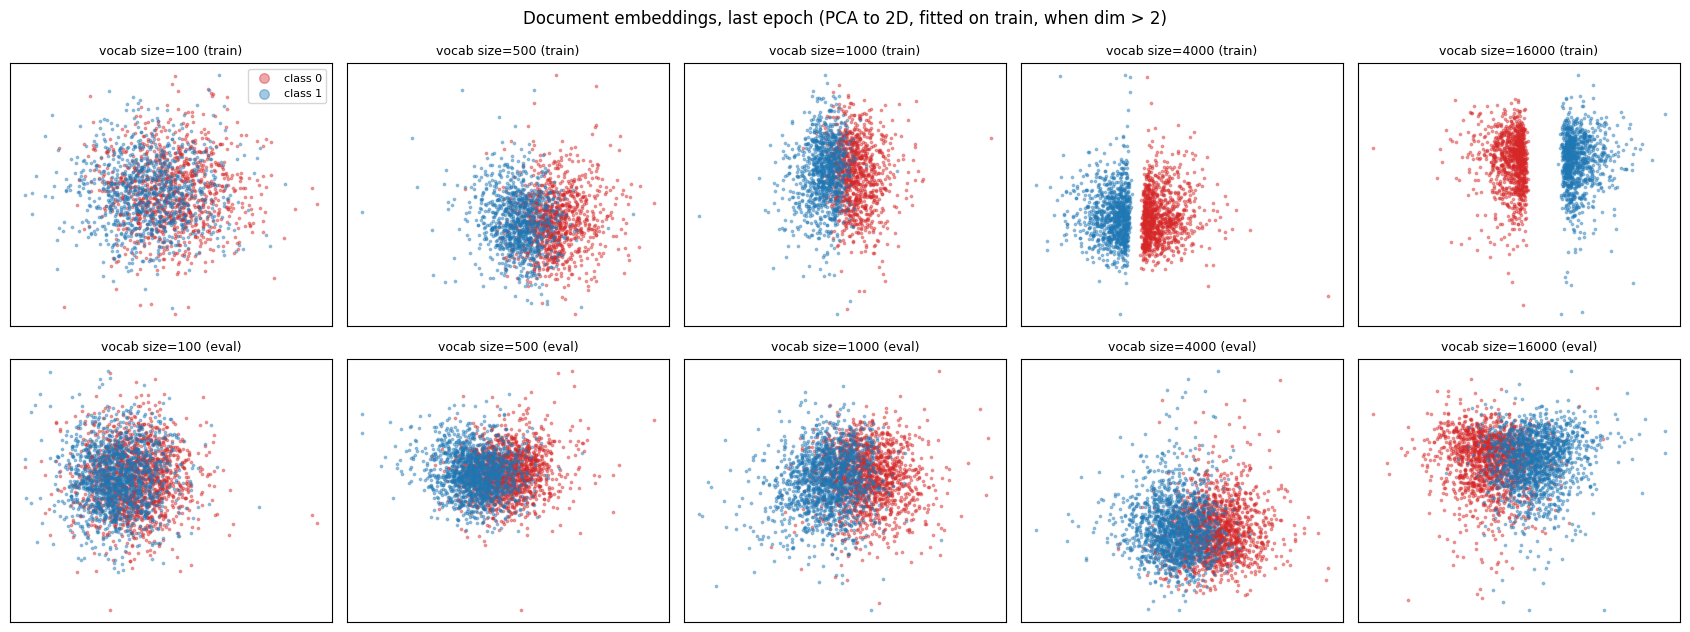

In [6]:
df_vocab_size, keep_vocab_size = sweep('vocab_size', [100, 500, 1000, 4000, 16000])
display(summarize(df_vocab_size))
plot_sweep('vocab_size', df_vocab_size, keep_vocab_size, 'vocab size')

## Experiment 2: dataset size

n_train=100 seed=0: final acc=0.536 best=0.536 (ep 20) 1s


n_train=100 seed=1: final acc=0.602 best=0.602 (ep 20) 1s


n_train=100 seed=2: final acc=0.581 best=0.581 (ep 20) 1s


n_train=500 seed=0: final acc=0.717 best=0.721 (ep 16) 1s


n_train=500 seed=1: final acc=0.722 best=0.724 (ep 18) 1s


...

n_train=5000 seed=2: final acc=0.791 best=0.815 (ep 5) 5s


n_train=25000 seed=0: final acc=0.818 best=0.836 (ep 2) 19s


n_train=25000 seed=1: final acc=0.814 best=0.838 (ep 2) 19s


n_train=25000 seed=2: final acc=0.813 best=0.835 (ep 2) 20s


,final_acc,final_std,best_acc,best_epoch,n_params,secs
value,,,,,,
100,0.5729,0.0337,0.5729,20.0000,128033,0.6890
500,0.7202,0.0026,0.7221,16.6667,128033,0.9309
2000,0.7775,0.0020,0.7856,7.3333,128033,2.1945
5000,0.7873,0.0044,0.8137,4.3333,128033,4.4398
25000,0.8153,0.0027,0.8366,2.0000,128033,19.5277


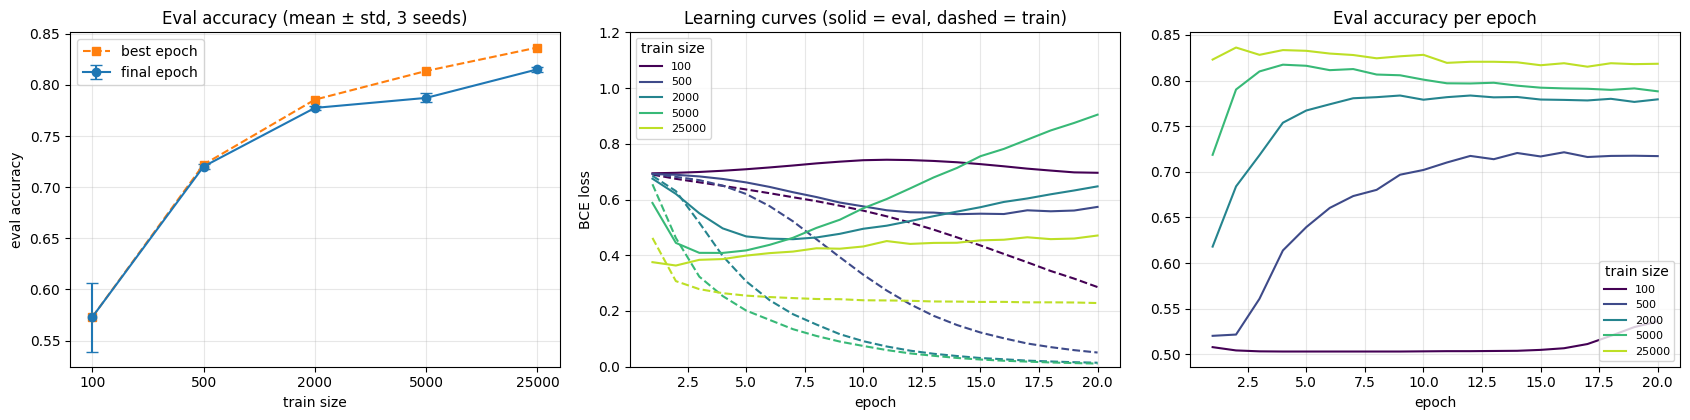

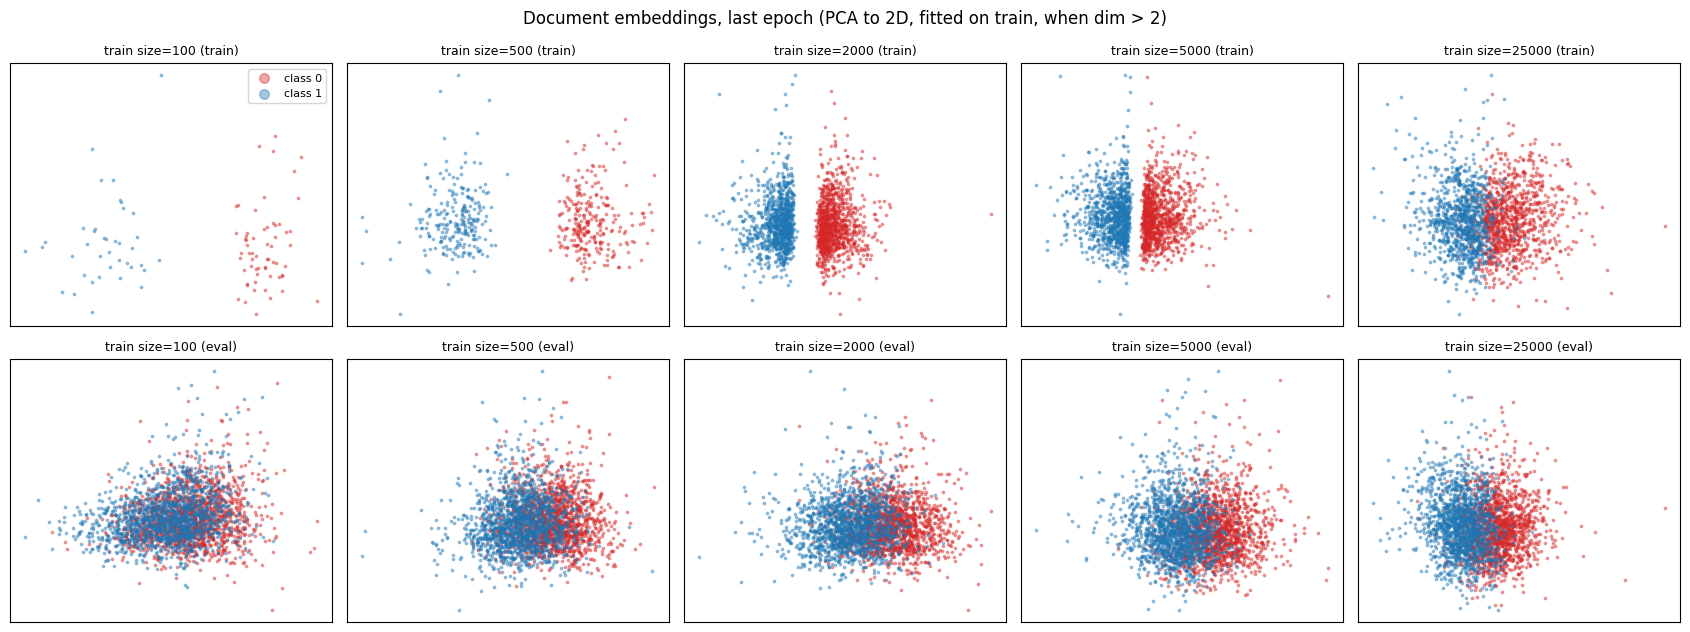

In [7]:
df_n_train, keep_n_train = sweep('n_train', [100, 500, 2000, 5000, 25000])
display(summarize(df_n_train))
plot_sweep('n_train', df_n_train, keep_n_train, 'train size')

## Experiment 3: embedding dimension

embedding_dim=2 seed=0: final acc=0.814 best=0.815 (ep 17) 2s


embedding_dim=2 seed=1: final acc=0.807 best=0.809 (ep 15) 2s


embedding_dim=2 seed=2: final acc=0.813 best=0.816 (ep 15) 2s


embedding_dim=8 seed=0: final acc=0.798 best=0.817 (ep 8) 2s


embedding_dim=8 seed=1: final acc=0.791 best=0.813 (ep 7) 2s


...

embedding_dim=128 seed=2: final acc=0.791 best=0.807 (ep 3) 10s


embedding_dim=512 seed=0: final acc=0.785 best=0.809 (ep 3) 189s


embedding_dim=512 seed=1: final acc=0.779 best=0.804 (ep 2) 40s


embedding_dim=512 seed=2: final acc=0.791 best=0.815 (ep 3) 37s


,final_acc,final_std,best_acc,best_epoch,n_params,secs
value,,,,,,
2,0.8113,0.0037,0.8133,15.6667,8003,2.1464
8,0.7967,0.0048,0.8143,8.0000,32009,2.4070
32,0.7873,0.0044,0.8137,4.3333,128033,4.6450
128,0.7887,0.0021,0.8109,3.6667,512129,10.3551
512,0.7849,0.0056,0.8092,2.6667,2048513,88.6396


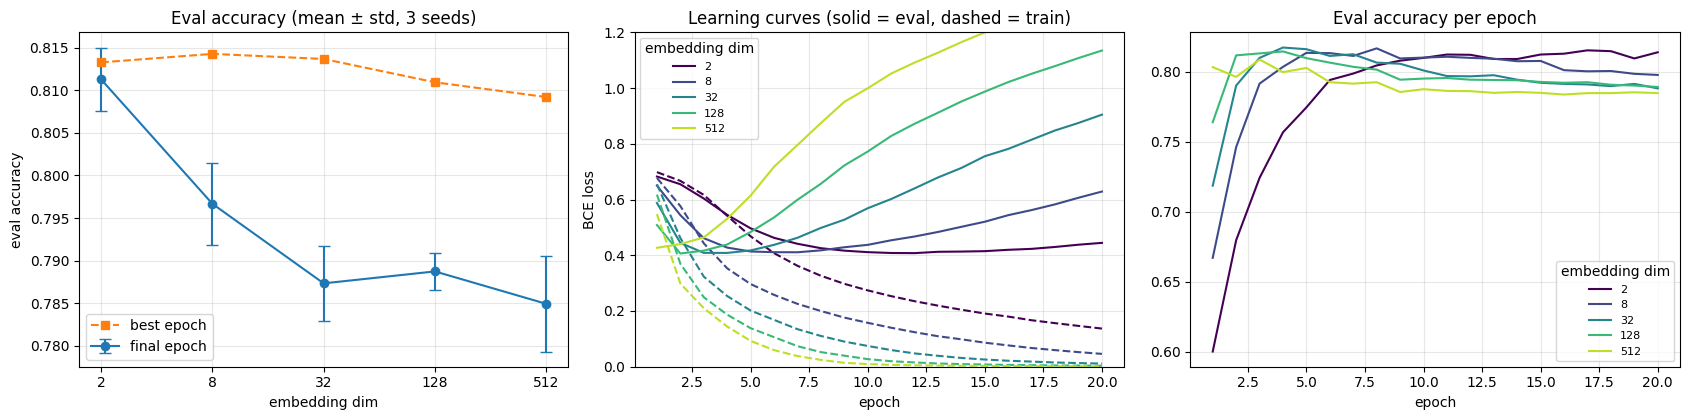

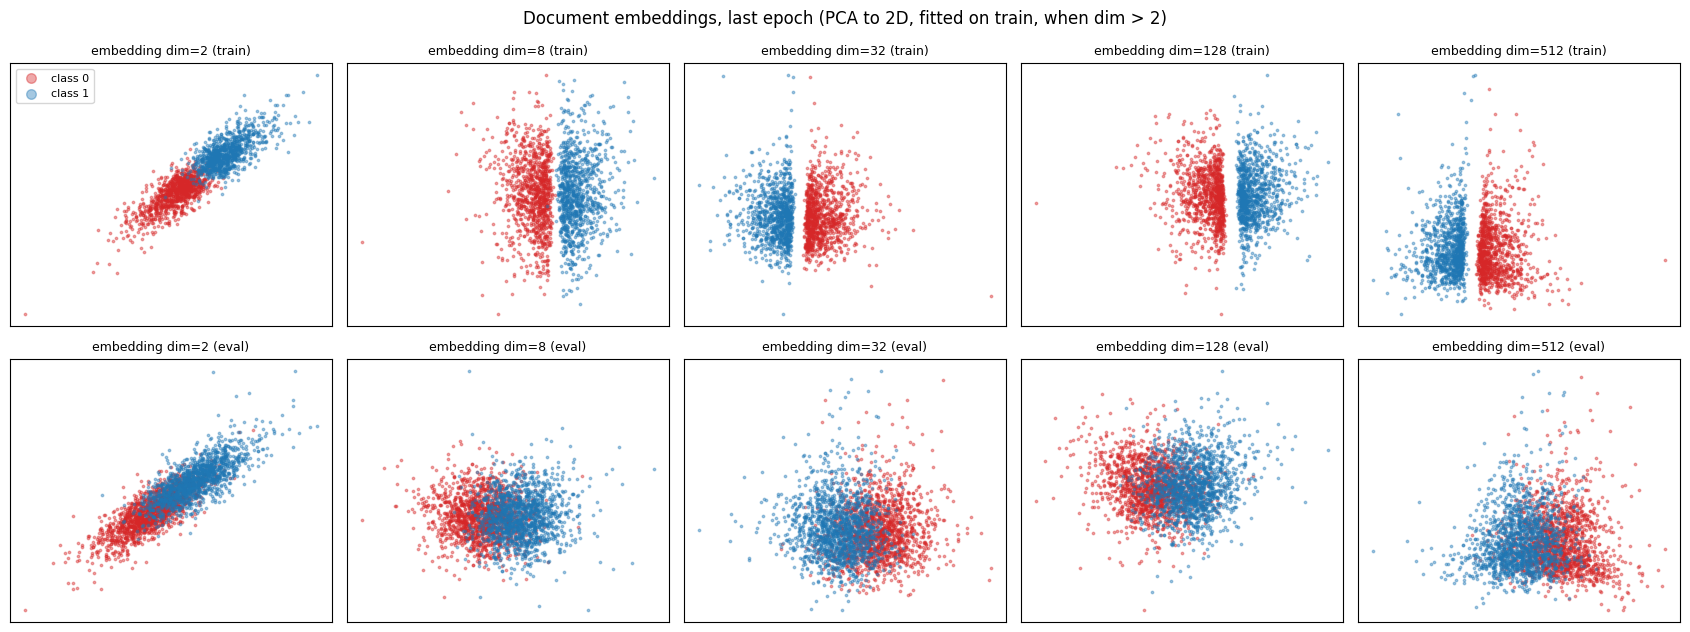

In [8]:
df_embedding_dim, keep_embedding_dim = sweep('embedding_dim', [2, 8, 32, 128, 512])
display(summarize(df_embedding_dim))
plot_sweep('embedding_dim', df_embedding_dim, keep_embedding_dim, 'embedding dim')

## Extension: sequence models instead of the mean
A bidirectional RNN/GRU/LSTM (hidden size 64 per direction) reads the embeddings, and its hidden states
are mean-pooled. Baseline data, vocab, and embedding size; 10 epochs; lr 2e-3; 1 seed (these models are slower).

{'model': 'mean', 'final_acc': np.float64(0.801), 'best_acc': 0.8174, 'best_epoch': 4, 'n_params': 128033, 'secs': 2}


{'model': 'rnn', 'final_acc': np.float64(0.7716), 'best_acc': 0.7778, 'best_epoch': 9, 'n_params': 140673, 'secs': 62}


{'model': 'gru', 'final_acc': np.float64(0.7714), 'best_acc': 0.7876, 'best_epoch': 7, 'n_params': 165761, 'secs': 151}


{'model': 'lstm', 'final_acc': np.float64(0.7812), 'best_acc': 0.7812, 'best_epoch': 10, 'n_params': 178305, 'secs': 192}


,model,final_acc,best_acc,best_epoch,n_params,secs
0,mean,0.8010,0.8174,4,128033,2
1,rnn,0.7716,0.7778,9,140673,62
2,gru,0.7714,0.7876,7,165761,151
3,lstm,0.7812,0.7812,10,178305,192


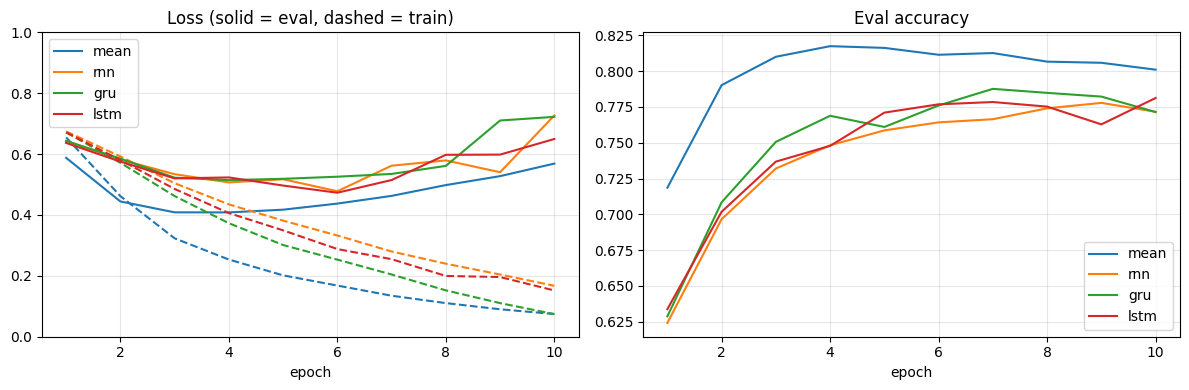

In [9]:
ext = []
keep_model = {}
for m in ['mean', 'rnn', 'gru', 'lstm']:
    r = run(**{**BASE, 'model': m}, seed=0, epochs=10, lr=2e-3 if m != 'mean' else LR)
    keep_model[m] = r
    ext.append(dict(model=m, final_acc=r['final_acc'], best_acc=r['best_acc'], best_epoch=r['best_epoch'],
                    n_params=r['n_params'], secs=round(r['secs'])))
    print(ext[-1])
df_model = pd.DataFrame(ext); df_model.to_csv(RES / 'model.csv', index=False)
display(df_model)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, r in keep_model.items():
    h = r['hist']
    l, = ax[0].plot(h.epoch, h.eval_loss, label=m); ax[0].plot(h.epoch, h.train_loss, ls='--', color=l.get_color())
    ax[1].plot(h.epoch, h.eval_acc, label=m)
ax[0].set_title('Loss (solid = eval, dashed = train)'); ax[0].set_ylim(0, 1); ax[1].set_title('Eval accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG / 'model_curves.png', dpi=130); plt.show()

## Conclusions
See the summary tables above and `results/*.csv`; conclusions are written in `README.md`.